In [16]:
import sys
print(sys.executable)

c:\Users\Norch\venvs\churn2\Scripts\python.exe


In [17]:
from pathlib import Path
import pandas as pd

csv = next(Path.cwd().rglob("telco_churn.csv"))
df = pd.read_csv(csv)
df.shape

(7043, 21)

In [18]:
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [19]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [20]:
df["Churn"].value_counts(normalize=True)

Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64

In [21]:
print("lignes:", len(df))
print("customerID uniques:", df["customerID"].nunique())

lignes: 7043
customerID uniques: 7043


In [22]:
print("doublons:", df["customerID"].duplicated().sum())
print("manquants:", df["customerID"].isna().sum())

doublons: 0
manquants: 0


In [23]:
total = df["customerID"].nunique()
partis = df.loc[df["Churn"] == "Yes", "customerID"].nunique()

print("clients total:", total)
print("clients partis:", partis)
print("taux de churn:", round(partis / total * 100, 1), "%")

clients total: 7043
clients partis: 1869
taux de churn: 26.5 %


In [24]:
df["churn_num"] = (df["Churn"] == "Yes").astype(int)

df.groupby("Contract")["churn_num"].agg(nb_clients="count", taux_churn="mean")

,nb_clients,taux_churn
Contract,,
Month-to-month,3875,0.427097
One year,1473,0.112695
Two year,1695,0.028319


In [25]:
df["tenure_groupe"] = pd.cut(df["tenure"], bins=[-1, 12, 24, 48, 72],
                             labels=["0-12 mois", "13-24", "25-48", "49-72"])

(df.groupby("tenure_groupe", observed=True)["churn_num"].mean() * 100).round(1)

tenure_groupe
0-12 mois    47.4
13-24        28.7
25-48        20.4
49-72         9.5
Name: churn_num, dtype: float64

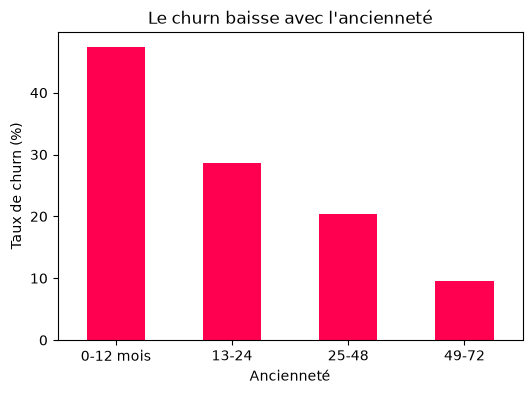

In [26]:
import matplotlib.pyplot as plt

taux = df.groupby("tenure_groupe", observed=True)["churn_num"].mean() * 100

ax = taux.plot(kind="bar", color="#ff0051", figsize=(6, 4))
ax.set_ylabel("Taux de churn (%)")
ax.set_xlabel("Ancienneté")
ax.set_title("Le churn baisse avec l'ancienneté")
plt.xticks(rotation=0)
plt.show()